In [1]:
import numpy as np
import cv2
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

In [2]:
oneD_kernel = cv2.getGaussianKernel(3, sigma=0)
twoD_kernel = oneD_kernel*oneD_kernel.T

print(twoD_kernel)
print(twoD_kernel.sum())


[[0.0625 0.125  0.0625]
 [0.125  0.25   0.125 ]
 [0.0625 0.125  0.0625]]
1.0


In [3]:
class RGB2GrayCNN(nn.Module):
    def __init__(self):
        super(RGB2GrayCNN, self).__init__()
        # 1x1 Conv layer to apply fixed weights
        self.conv = nn.Conv2d(in_channels=3, out_channels=1, kernel_size=1, stride=1, padding=0, bias=False)
        
        # Set the weights manually to match the grayscale conversion formula
        weights = torch.tensor([[[[0.299]], [[0.587]], [[0.114]]]])  # Shape: (1, 3, 1, 1)
        self.conv.weight = nn.Parameter(weights, requires_grad=False)  # Fix the weights

    def forward(self, x):
        return self.conv(x)


class RGB2GrayGaussianCNN(nn.Module):
    def __init__(self):
        super(RGB2GrayGaussianCNN, self).__init__()
        
        # 1x1 Conv layer to apply fixed grayscale conversion
        self.rgb2gray = nn.Conv2d(in_channels=3, out_channels=1, kernel_size=1, stride=1, padding=0, bias=False)
        gray_weights = torch.tensor([[[[0.299]], [[0.587]], [[0.114]]]])  # Shape: (1, 3, 1, 1)
        self.rgb2gray.weight = nn.Parameter(gray_weights, requires_grad=False)

        # 3x3 Conv layer for Gaussian blurring
        self.gaussian_blur = nn.Conv2d(in_channels=1, out_channels=1, kernel_size=3, stride=1, padding=1, bias=False)
        gaussian_weights = torch.tensor(
            [[[[0.0625, 0.125, 0.0625],
               [0.125,  0.25,  0.125],
               [0.0625, 0.125, 0.0625]]]]
        )  # Shape: (1, 1, 3, 3)
        self.gaussian_blur.weight = nn.Parameter(gaussian_weights, requires_grad=False)

    def forward(self, x):
        x = self.rgb2gray(x)  # Convert RGB to grayscale
        x = self.gaussian_blur(x)  # Apply Gaussian blur
        return x


class RGB2GrayRGB(nn.Module):
    def __init__(self):
        super(RGB2GrayRGB, self).__init__()
        
        # 1x1 Conv layer to apply fixed grayscale conversion
        self.rgb2gray = nn.Conv2d(in_channels=3, out_channels=1, kernel_size=1, stride=1, padding=0, bias=False)
        gray_weights = torch.tensor([[[[0.299]], [[0.587]], [[0.114]]]])  # Shape: (1, 3, 1, 1)
        self.rgb2gray.weight = nn.Parameter(gray_weights, requires_grad=False)

        # 3x3 Conv layer for Gaussian blurring
        self.gaussian_blur = nn.Conv2d(in_channels=1, out_channels=1, kernel_size=3, stride=1, padding=1, bias=False)
        gaussian_weights = torch.tensor(
            [[[[0.0625, 0.125, 0.0625],
               [0.125,  0.25,  0.125],
               [0.0625, 0.125, 0.0625]]]]
        )  # Shape: (1, 1, 3, 3)
        self.gaussian_blur.weight = nn.Parameter(gaussian_weights, requires_grad=False)

    def forward(self, x):
        x = self.rgb2gray(x)  # Convert RGB to grayscale
        x = self.gaussian_blur(x)  # Apply Gaussian blur
        x = x.repeat(1, 3, 1, 1)  # Duplicate the grayscale channel to create an RGB image
        return x


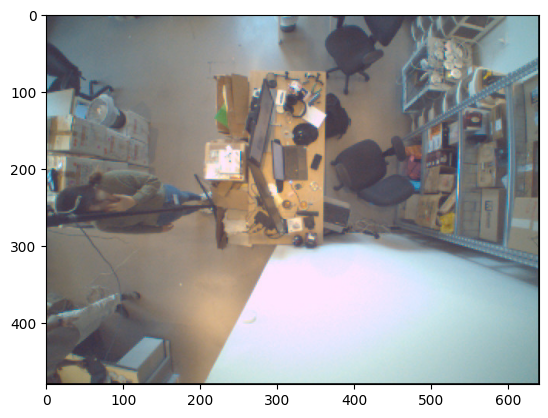

In [6]:
img = cv2.imread('cam4_poc_15/images/val/250_cam4_.jpg')
img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

plt.imshow(img)

In [7]:
net = RGB2GrayCNN()
res = net(torch.from_numpy(img).permute(2, 0, 1).unsqueeze(0).float() / 255.0)
res = res.squeeze(0).permute(1, 2, 0).detach().numpy()

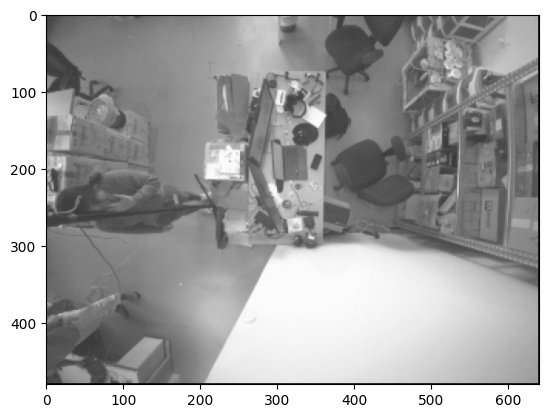

In [8]:
plt.imshow(res, cmap='gray')

In [9]:
(cv2.cvtColor(img, cv2.COLOR_RGB2GRAY) - (res[:, :, 0] * 255).astype(np.uint8)).mean()  # Should be 0

0.5053515625

In [10]:
net = RGB2GrayGaussianCNN()
res = net(torch.from_numpy(img).permute(2, 0, 1).unsqueeze(0).float() / 255.0)
res = res.squeeze(0).permute(1, 2, 0).detach().numpy()
res = (res[:, :, 0] * 255).astype(np.uint8)

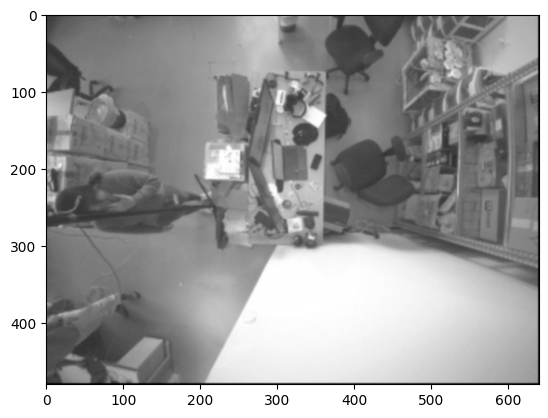

In [11]:
plt.imshow(res, cmap='gray')

In [12]:
(cv2.GaussianBlur(cv2.cvtColor(img, cv2.COLOR_RGB2GRAY), (3, 3), 0) - res).mean()  # Should be 0

0.7808951822916667

In [13]:
net = RGB2GrayRGB()
res = net(torch.from_numpy(img).permute(2, 0, 1).unsqueeze(0).float() / 255.0)
res = res.squeeze(0).permute(1, 2, 0).detach().numpy()
res = (res * 255).astype(np.uint8)

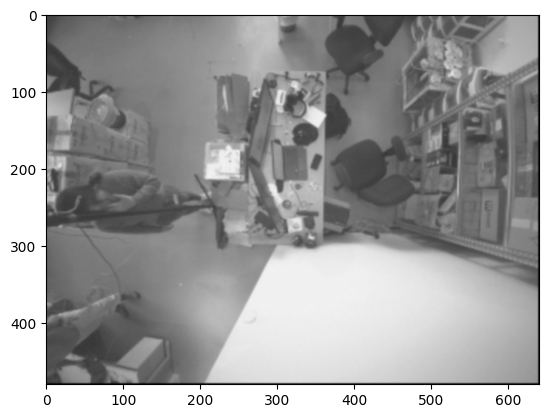

In [14]:
plt.imshow(res);